# Pràctica 2: Aprenentatge no supervisat
En aquesta pràctica treballarem amb dos conjunts de dades, un de sintètic i un de real, amb l’objectiu d’analitzar-ne l’estructura interna mitjançant tècniques d’aprenentatge no supervisat.

Primer llegirem i prepararem les dades, separant les variables utilitzades pels models de la informació de classe i localització, que només es farà servir per interpretar els resultats. Després aplicarem diferents mètodes de reducció de dimensionalitat, clustering i visualització, com PCA, t-SNE, k-means, clustering jeràrquic, autoencoders i SOM, i compararem els resultats obtinguts amb les classes reals.

## 1. Lectura de les dades

In [88]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [89]:
df_synthetic = pd.read_csv("A2-data/A2-synthetic.txt", sep=",", na_filter=False)
df_real = pd.read_csv("A2-data/A2-real.txt", sep=";", na_filter=False)

print("Synthetic shape:", df_synthetic.shape)
print("Real shape:", df_real.shape)
display(df_synthetic.head(), df_real.head())

Synthetic shape: (360, 5)
Real shape: (333, 7)


,x1,x2,x3,x4,class
0,-0.031676,-9.912054,-0.579436,-1.044239,1
1,0.002526,6.172456,3.288339,-1.006427,5
2,0.183123,-0.387841,6.236470,-1.691491,2
3,-0.042262,-1.996272,-1.655302,-2.995311,1
4,-0.062811,-0.417072,6.657475,-3.633134,4


,BL,BD,FL,BM,S,Location,Class
0,34.5,18.1,187,2900,1,L2,C1
1,38.8,20.0,190,3950,0,L3,C1
2,45.1,14.5,207,5050,1,L2,C2
3,34.6,21.1,198,4400,0,L1,C1
4,40.6,19.0,199,4000,0,L1,C1


In [90]:
display(df_synthetic.info(), df_real.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 360 entries, 0 to 359
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x1      360 non-null    float64
 1   x2      360 non-null    float64
 2   x3      360 non-null    float64
 3   x4      360 non-null    float64
 4   class   360 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 14.2 KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 333 entries, 0 to 332
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   BL        333 non-null    float64
 1   BD        333 non-null    float64
 2   FL        333 non-null    int64  
 3   BM        333 non-null    int64  
 4   S         333 non-null    int64  
 5   Location  333 non-null    object 
 6   Class     333 non-null    object 
dtypes: float64(2), int64(3), object(2)
memory usage: 18.3+ KB


None

None

En el conjunt real, les variables `Location` i `Class` apareixen com a categòriques. Seguint l’enunciat, no s’utilitzen en l’aprenentatge no supervisat: `Class` es reserva per comparar i pintar els resultats, i `Location` només es pot utilitzar com a informació auxiliar en algunes visualitzacions.

In [91]:
display(df_synthetic[["x1", "x2", "x3", "x4"]].describe(), df_real[["BL", "BD", "FL", "BM", "S"]].describe())

,x1,x2,x3,x4
count,360.000000,360.000000,360.000000,360.000000
mean,0.030880,0.685121,3.973543,-0.318865
std,0.377520,4.900030,4.050409,3.321348
min,-0.819698,-9.912054,-4.573732,-7.954909
25%,-0.140746,-2.033918,0.610788,-2.694196
50%,0.002011,0.214840,4.988976,-0.246234
75%,0.242461,4.182701,7.123379,1.665129
max,0.922136,10.812646,11.604825,7.976116


,BL,BD,FL,BM,S
count,333.000000,333.000000,333.000000,333.000000,333.000000
mean,43.992793,17.164865,200.966967,4207.057057,0.495495
std,5.468668,1.969235,14.015765,805.215802,0.500732
min,32.100000,13.100000,172.000000,2700.000000,0.000000
25%,39.500000,15.600000,190.000000,3550.000000,0.000000
50%,44.500000,17.300000,197.000000,4050.000000,0.000000
75%,48.600000,18.700000,213.000000,4775.000000,1.000000
max,59.600000,21.500000,231.000000,6300.000000,1.000000


## 2. Pre-processament dades

Com que l’enunciat indica que els dos conjunts de dades ja han estat tractats per eliminar outliers, dades no físiques i dades incompletes, no s’aplica cap filtratge addicional. El pre-processament consisteix a separar les variables numèriques de les variables auxiliars (`class`, `Class` i `Location`) i a estandarditzar les variables d’entrada mitjançant z-score. Això permet que totes les variables tinguin mitjana 0 i desviació estàndard 1, evitant que les variables amb valors més grans dominin els mètodes basats en distàncies o variància.

In [92]:
X_synthetic = df_synthetic[["x1", "x2", "x3", "x4"]]
y_synthetic = df_synthetic["class"]

X_real = df_real[["BL", "BD", "FL", "BM", "S"]]
y_real = df_real["Class"]
location_real = df_real["Location"]

Apliquem **z-score** per estandaritzar els valors:

In [93]:
X_synthetic_z = (X_synthetic - X_synthetic.mean()) / X_synthetic.std()
X_real_z = (X_real - X_real.mean()) / X_real.std()

In [94]:
display(X_synthetic_z.describe().round(3), X_real_z.describe().round(3))

,x1,x2,x3,x4
count,360.000,360.000,360.000,360.000
mean,-0.000,-0.000,-0.000,-0.000
std,1.000,1.000,1.000,1.000
min,-2.253,-2.163,-2.110,-2.299
25%,-0.455,-0.555,-0.830,-0.715
50%,-0.076,-0.096,0.251,0.022
75%,0.560,0.714,0.778,0.597
max,2.361,2.067,1.884,2.497


,BL,BD,FL,BM,S
count,333.000,333.000,333.000,333.000,333.000
mean,0.000,0.000,0.000,-0.000,-0.000
std,1.000,1.000,1.000,1.000,1.000
min,-2.175,-2.064,-2.067,-1.872,-0.990
25%,-0.822,-0.795,-0.782,-0.816,-0.990
50%,0.093,0.069,-0.283,-0.195,-0.990
75%,0.842,0.780,0.859,0.705,1.008
max,2.854,2.201,2.143,2.599,1.008


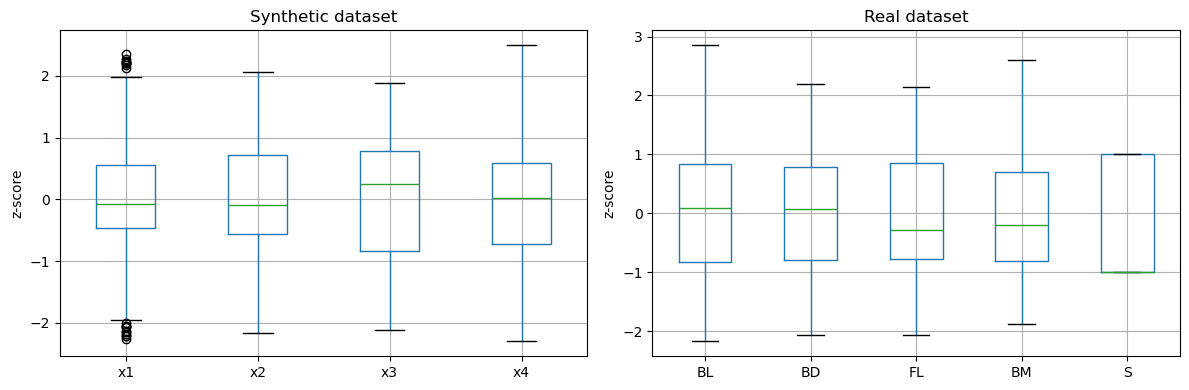

In [95]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

X_synthetic_z.boxplot(ax=axes[0])
axes[0].set_title("Synthetic dataset")
axes[0].set_ylabel("z-score")

X_real_z.boxplot(ax=axes[1])
axes[1].set_title("Real dataset")
axes[1].set_ylabel("z-score")

plt.tight_layout()
plt.show()

Mirem per curiositat la distribució de les dades, ja que les dades ja han estat tractades prèviament.

## 3. Tècniques d'aprenentatge no supervisat

### 3.1 PCA
El PCA permet projectar les dades en un espai de menor dimensió mantenint la màxima variància possible. Les classes reals només s’utilitzen per pintar els punts i interpretar visualment els resultats.

In [96]:
from sklearn.decomposition import PCA

In [97]:
pca_synthetic = PCA()
pca_real = PCA()

X_synthetic_pca_all = pca_synthetic.fit_transform(X_synthetic_z)
X_real_pca_all = pca_real.fit_transform(X_real_z)

# l'enunciat demana dues dimensions
X_synthetic_pca = X_synthetic_pca_all[:, :2]
X_real_pca = X_real_pca_all[:, :2]

In [98]:
df_synthetic_pca = pd.DataFrame(X_synthetic_pca, columns=["d1", "d2"])
df_synthetic_pca["class"] = y_synthetic.values

df_real_pca = pd.DataFrame(X_real_pca, columns=["d1", "d2"])
df_real_pca["Class"] = y_real.values
df_real_pca["Location"] = location_real.values

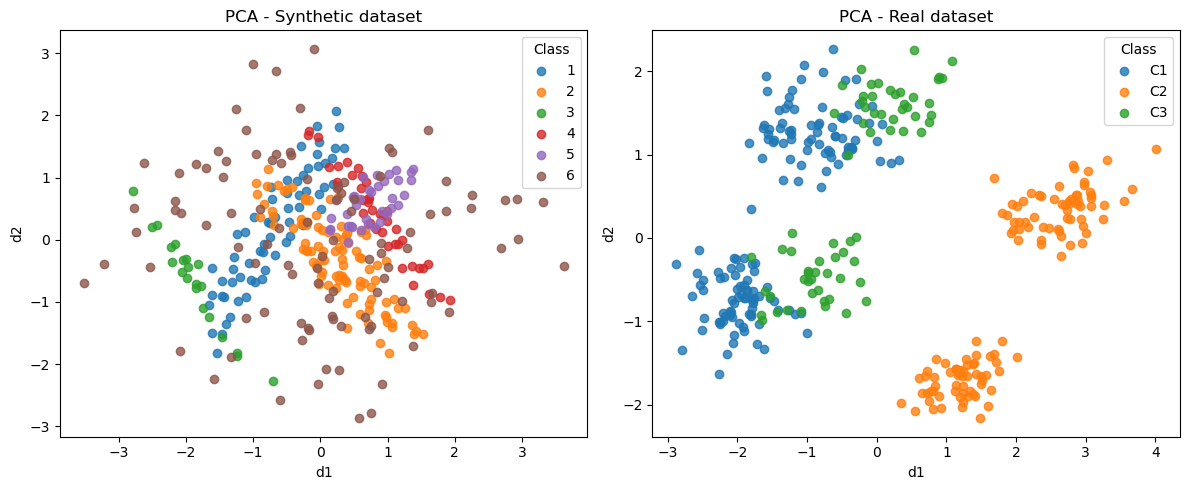

In [99]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for cls in sorted(df_synthetic_pca["class"].unique()):
    subset = df_synthetic_pca[df_synthetic_pca["class"] == cls]
    axes[0].scatter(subset["d1"], subset["d2"], label=cls, alpha=0.8)

axes[0].set_title("PCA - Synthetic dataset")
axes[0].set_xlabel("d1")
axes[0].set_ylabel("d2")
axes[0].legend(title="Class")

for cls in sorted(df_real_pca["Class"].unique()):
    subset = df_real_pca[df_real_pca["Class"] == cls]
    axes[1].scatter(subset["d1"], subset["d2"], label=cls, alpha=0.8)

axes[1].set_title("PCA - Real dataset")
axes[1].set_xlabel("d1")
axes[1].set_ylabel("d2")
axes[1].legend(title="Class")

plt.tight_layout()
plt.show()

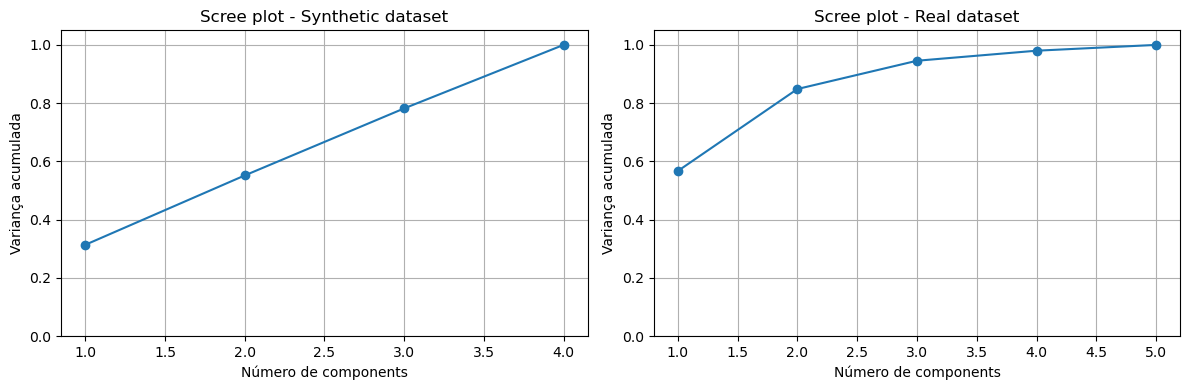

In [100]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    range(1, len(pca_synthetic.explained_variance_ratio_) + 1),
    np.cumsum(pca_synthetic.explained_variance_ratio_),
    marker="o"
)
axes[0].set_title("Scree plot - Synthetic dataset")
axes[0].set_xlabel("Número de components")
axes[0].set_ylabel("Variança acumulada")
axes[0].set_ylim(0, 1.05)
axes[0].grid(True)

axes[1].plot(
    range(1, len(pca_real.explained_variance_ratio_) + 1),
    np.cumsum(pca_real.explained_variance_ratio_),
    marker="o"
)
axes[1].set_title("Scree plot - Real dataset")
axes[1].set_xlabel("Número de components")
axes[1].set_ylabel("Variança acumulada")
axes[1].set_ylim(0, 1.05)
axes[1].grid(True)

plt.tight_layout()
plt.show()

En el conjunt sintètic, la projecció PCA en dues dimensions mostra una separació parcial de les classes, però amb força solapament entre diversos grups. El scree plot indica que les dues primeres components acumulen una mica més del 50% de la variància, de manera que la representació en dues dimensions no conserva tota la informació del conjunt original.

En el conjunt real, la projecció PCA mostra una separació més clara entre algunes classes, especialment la classe C2, que queda força diferenciada de C1 i C3. En aquest cas, les dues primeres components acumulen aproximadament el 85% de la variància, per tant la projecció 2D conserva una part important de la informació original.

### 3.2 t-SNE

El t-SNE és una tècnica de reducció de dimensionalitat no lineal orientada principalment a la visualització. En aquest apartat es projectaran els dos conjunts de dades estandarditzats en dues dimensions utilitzant diferents valors de `perplexity`. Les classes reals només s’utilitzen per pintar els punts i interpretar visualment els resultats.

In [101]:
from sklearn.manifold import TSNE

In [102]:
perplexities = [5, 10, 30, 50]

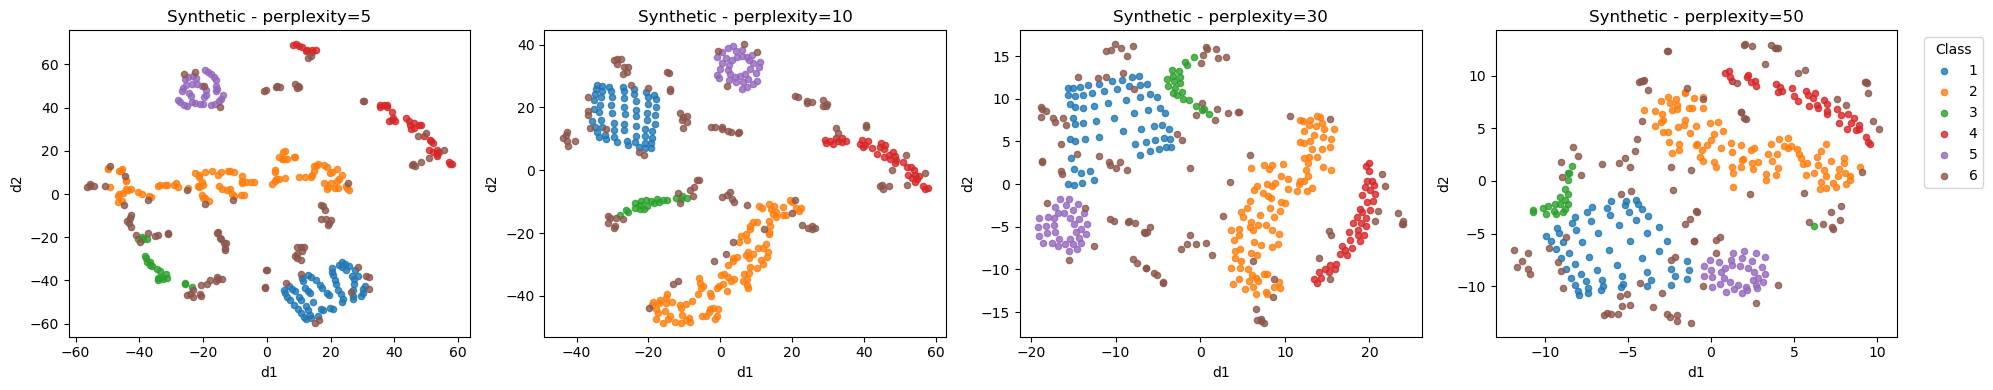

In [103]:
#codi pel conjunt synthetic
fig, axes = plt.subplots(1, len(perplexities), figsize=(20, 4))

for ax, perplexity in zip(axes, perplexities):
    tsne = TSNE(
        n_components=2,
        perplexity=perplexity,
        random_state=42,
        init="pca",
        learning_rate="auto"
    )
    
    X_tsne = tsne.fit_transform(X_synthetic_z)
    
    df_tsne = pd.DataFrame(X_tsne, columns=["d1", "d2"])
    df_tsne["class"] = y_synthetic.values
    
    for cls in sorted(df_tsne["class"].unique()):
        subset = df_tsne[df_tsne["class"] == cls]
        ax.scatter(subset["d1"], subset["d2"], label=cls, alpha=0.8, s=20)
    
    ax.set_title(f"Synthetic - perplexity={perplexity}")
    ax.set_xlabel("d1")
    ax.set_ylabel("d2")

axes[-1].legend(title="Class", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

El resultat del t-SNE canvia de manera visible segons el valor de `perplexity`. Amb valors baixos, com 5 o 10, apareixen grups més separats i locals, però també més fragmentats. Amb valors més alts, com 30 o 50, la representació és més compacta i conserva millor una estructura global. Algunes classes, com la 2, 4 i 5, formen agrupacions relativament diferenciades, mentre que la classe 6 apareix més dispersa i barrejada amb altres classes.

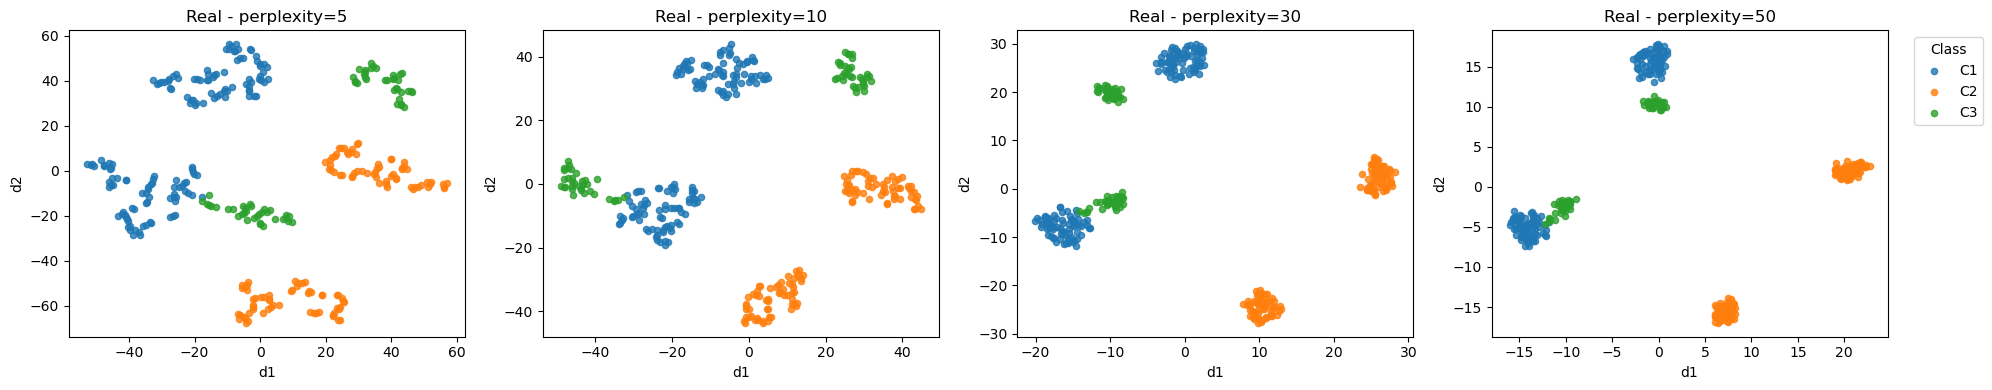

In [104]:
#codi pel conjunt real
fig, axes = plt.subplots(1, len(perplexities), figsize=(20, 4))

for ax, perplexity in zip(axes, perplexities):
    tsne = TSNE(
        n_components=2,
        perplexity=perplexity,
        random_state=42,
        init="pca",
        learning_rate="auto"
    )
    
    X_tsne = tsne.fit_transform(X_real_z)
    
    df_tsne = pd.DataFrame(X_tsne, columns=["d1", "d2"])
    df_tsne["Class"] = y_real.values
    
    for cls in sorted(df_tsne["Class"].unique()):
        subset = df_tsne[df_tsne["Class"] == cls]
        ax.scatter(subset["d1"], subset["d2"], label=cls, alpha=0.8, s=20)
    
    ax.set_title(f"Real - perplexity={perplexity}")
    ax.set_xlabel("d1")
    ax.set_ylabel("d2")

axes[-1].legend(title="Class", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

En el conjunt real, el t-SNE mostra una separació clara entre diverses zones de l’espai projectat. La classe C2 queda força diferenciada de la resta en tots els valors de `perplexity`, mentre que C1 i C3 apareixen més properes en algunes regions. Amb `perplexity=5` i `10` la representació queda més fragmentada, amb diversos grups separats. Amb `perplexity=30` i `50`, l’estructura és més compacta i estable, mantenint una separació visual clara entre les classes.

## 3.3 k-means

El k-means és un mètode de clustering que agrupa les dades en k grups a partir de la distància als centroides. En aquest apartat s’aplica k-means amb diferents valors de k i es representen els clusters obtinguts utilitzant com a coordenades les dues primeres components del PCA.

In [105]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

In [106]:
k_values = range(2, 10)

S’ha fixat K = 9 i s’ha aplicat k-means per a tots els valors de k entre 2 i 9. Això permet comparar agrupacions amb menys, igual o més clusters que el nombre de classes reals dels conjunts de dades.

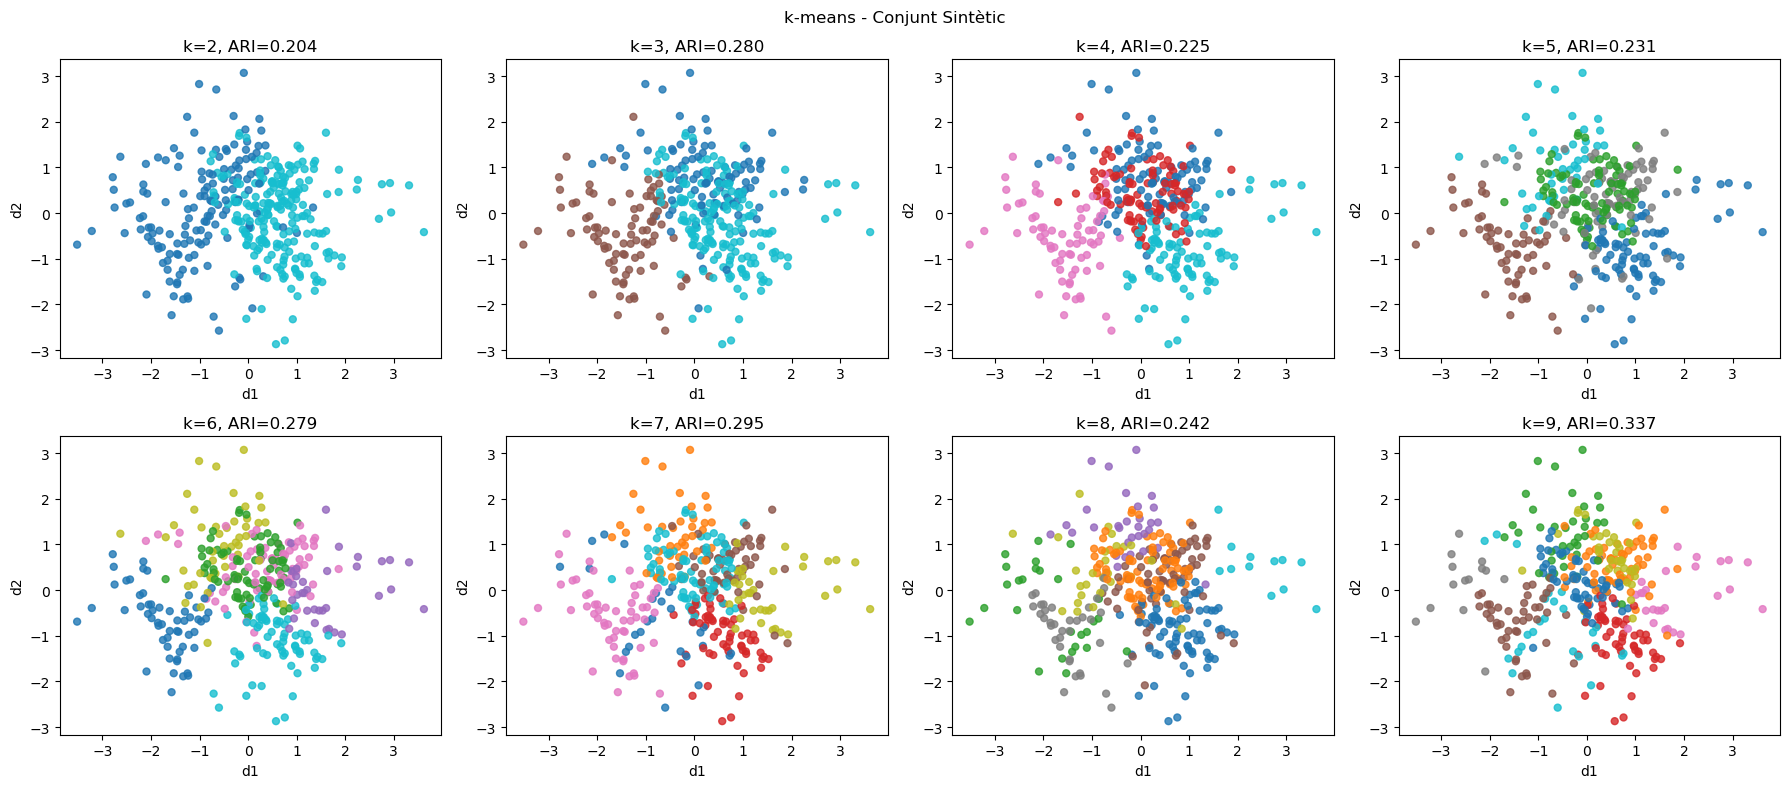

In [107]:
#codi pel conjunt synthetic

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.ravel()

synthetic_kmeans_results = {}

for ax, k in zip(axes, k_values):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    clusters = kmeans.fit_predict(X_synthetic_z)
    
    synthetic_kmeans_results[k] = clusters
    
    ax.scatter(
        df_synthetic_pca["d1"],
        df_synthetic_pca["d2"],
        c=clusters,
        cmap="tab10",
        alpha=0.8,
        s=25
    )
    
    ari = adjusted_rand_score(y_synthetic, clusters)
    ax.set_title(f"k={k}, ARI={ari:.3f}")
    ax.set_xlabel("d1")
    ax.set_ylabel("d2")

plt.suptitle("k-means - Conjunt Sintètic")
plt.tight_layout()
plt.show()

Els valors d’ARI són relativament baixos per a tots els valors de k provats, fet que indica que els clusters obtinguts per k-means no coincideixen completament amb les classes reals. El cas k=6 és especialment rellevant perquè el conjunt conté 6 classes reals, però l’ARI obtingut continua sent moderat. El valor més alt d’ARI apareix amb k=9, cosa que suggereix que k-means divideix algunes classes en subgrups segons la seva distribució geomètrica. Això és coherent amb el solapament observat en la projecció PCA.

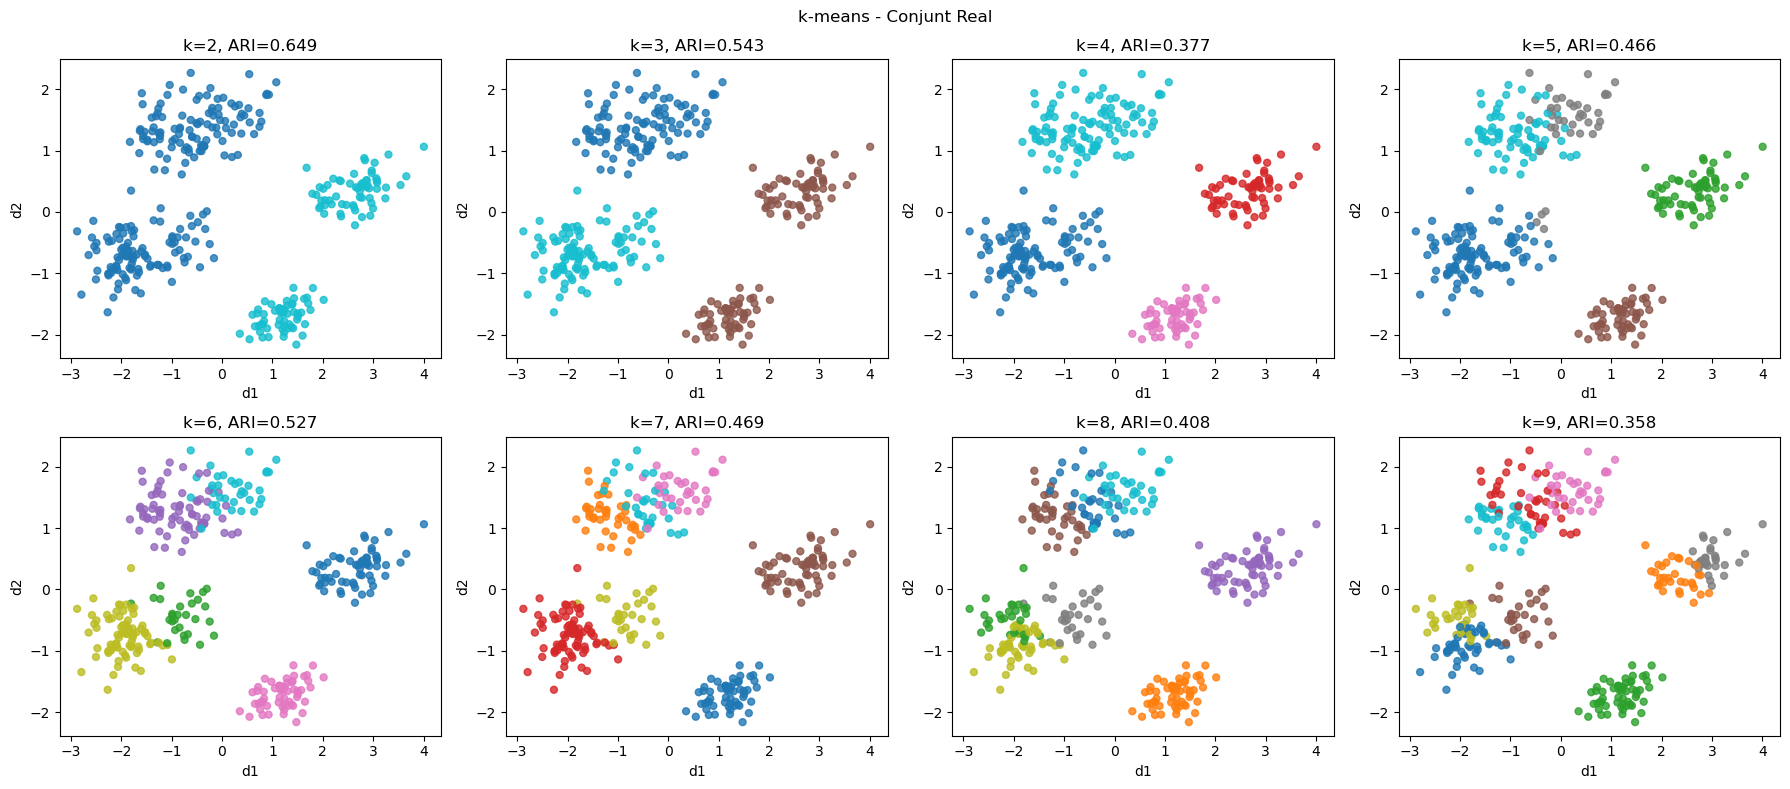

In [108]:
#codi pel conjunt real

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.ravel()

real_kmeans_results = {}

for ax, k in zip(axes, k_values):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    clusters = kmeans.fit_predict(X_real_z)
    
    real_kmeans_results[k] = clusters
    
    ax.scatter(
        df_real_pca["d1"],
        df_real_pca["d2"],
        c=clusters,
        cmap="tab10",
        alpha=0.8,
        s=25
    )
    
    ari = adjusted_rand_score(y_real, clusters)
    ax.set_title(f"k={k}, ARI={ari:.3f}")
    ax.set_xlabel("d1")
    ax.set_ylabel("d2")

plt.suptitle("k-means - Conjunt Real")
plt.tight_layout()
plt.show()

En el conjunt real, el valor més alt d’ARI s’obté amb k=2, tot i que el conjunt té tres classes reals. Això indica que, segons la geometria de les dades estandarditzades, k-means identifica dues grans agrupacions més clares que no pas tres grups coincidents exactament amb les classes. Amb k=3, que és el nombre de classes reals, l’ARI continua sent relativament alt, però inferior al de k=2. Per a valors més grans de k, els grups principals es divideixen en subclusters i la correspondència amb les classes reals tendeix a empitjorar.

## 3.4 Agglomerative Hierarchical Clustering

El clustering jeràrquic aglomeratiu construeix una jerarquia de grups a partir de les distàncies entre patrons. En aquest apartat s’utilitza la distància euclidiana i es comparen dos criteris d’enllaç: unweighted average, també conegut com UPGMA, i complete linkage.

In [109]:
from scipy.cluster.hierarchy import linkage, dendrogram

In [110]:
#definim una funció per pintar les fulles

def color_dendrogram_labels(ax, color_map):
    for label in ax.get_xmajorticklabels():
        label_text = label.get_text()
        if label_text in color_map:
            label.set_color(color_map[label_text])

In [111]:
#mapa de colors
synthetic_class_colors = {
    "1": "tab:blue",
    "2": "tab:orange",
    "3": "tab:green",
    "4": "tab:red",
    "5": "tab:purple",
    "6": "tab:brown"
}

real_class_colors = {
    "C1": "tab:blue",
    "C2": "tab:orange",
    "C3": "tab:green"
}

En els dendrogrames, el color de les etiquetes de les fulles indica la classe real de cada patró. Les línies del dendrograma representen l’estructura jeràrquica obtinguda pel mètode d’enllaç corresponent.

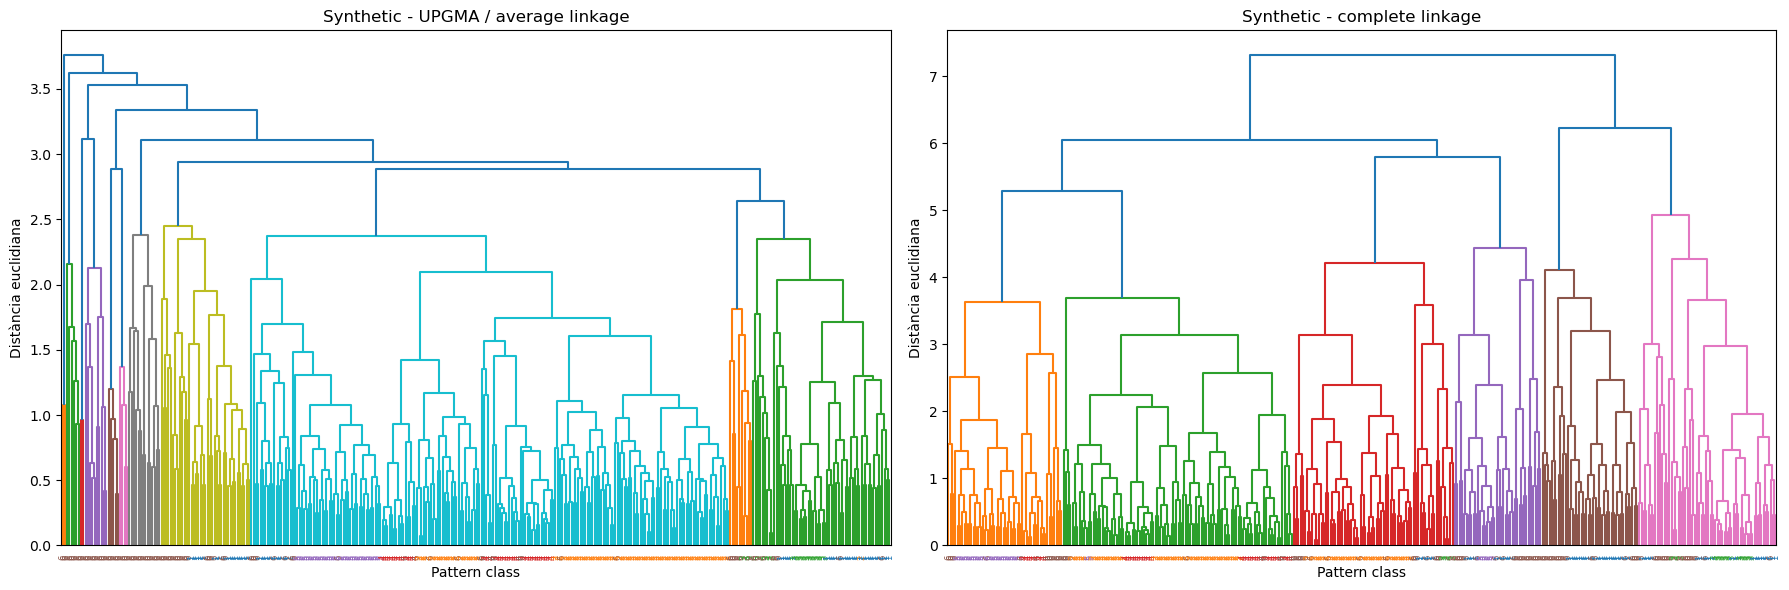

In [112]:
#codi pel conjunt synthetic

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

Z_synthetic_average = linkage(X_synthetic_z, method="average", metric="euclidean")
Z_synthetic_complete = linkage(X_synthetic_z, method="complete", metric="euclidean")

dendrogram(
    Z_synthetic_average,
    labels=y_synthetic.astype(str).values,
    leaf_rotation=90,
    leaf_font_size=6,
    ax=axes[0]
)
axes[0].set_title("Synthetic - UPGMA / average linkage")
axes[0].set_xlabel("Pattern class")
axes[0].set_ylabel("Distància euclidiana")

dendrogram(
    Z_synthetic_complete,
    labels=y_synthetic.astype(str).values,
    leaf_rotation=90,
    leaf_font_size=6,
    ax=axes[1]
)

color_dendrogram_labels(axes[0], synthetic_class_colors)
color_dendrogram_labels(axes[1], synthetic_class_colors)
axes[1].set_title("Synthetic - complete linkage")
axes[1].set_xlabel("Pattern class")
axes[1].set_ylabel("Distància euclidiana")

plt.tight_layout()
plt.show()

Els dendrogrames mostren una barreja important de classes en diverses branques. Això indica que la jerarquia construïda a partir de la `distància euclidiana` no separa perfectament les classes reals. El mètode `complete linkage` genera grups més compactes i separats a distàncies més altes, mentre que l’average linkage produeix una estructura més gradual.

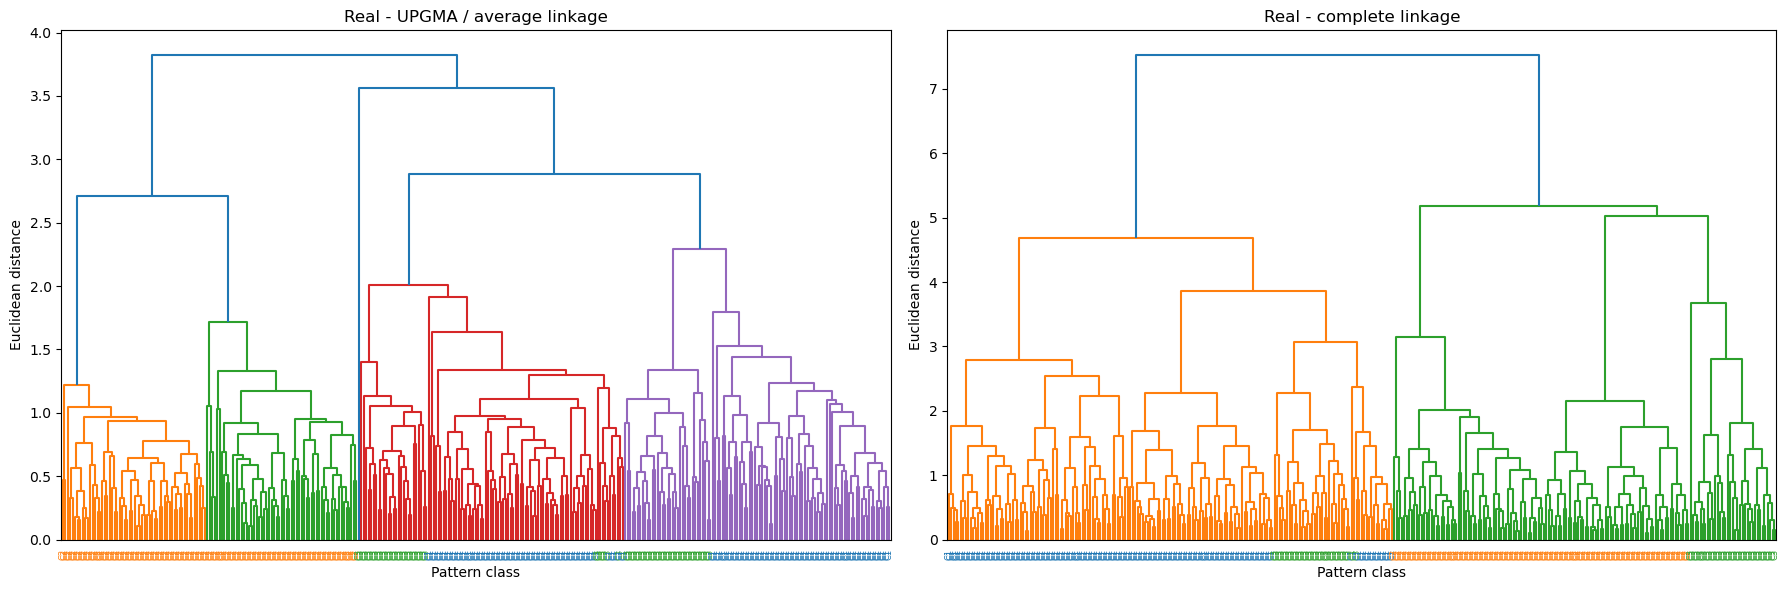

In [113]:
#codi pel conjunt real

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

Z_real_average = linkage(X_real_z, method="average", metric="euclidean")
Z_real_complete = linkage(X_real_z, method="complete", metric="euclidean")

dendrogram(
    Z_real_average,
    labels=y_real.astype(str).values,
    leaf_rotation=90,
    leaf_font_size=6,
    ax=axes[0]
)
axes[0].set_title("Real - UPGMA / average linkage")
axes[0].set_xlabel("Pattern class")
axes[0].set_ylabel("Euclidean distance")

dendrogram(
    Z_real_complete,
    labels=y_real.astype(str).values,
    leaf_rotation=90,
    leaf_font_size=6,
    ax=axes[1]
)

color_dendrogram_labels(axes[0], real_class_colors)
color_dendrogram_labels(axes[1], real_class_colors)
axes[1].set_title("Real - complete linkage")
axes[1].set_xlabel("Pattern class")
axes[1].set_ylabel("Euclidean distance")

plt.tight_layout()
plt.show()

En el conjunt real, els dendrogrames mostren una estructura més clara que en el conjunt sintètic. Les fulles corresponents a la classe C2 apareixen força agrupades en una zona diferenciada, mentre que C1 i C3 presenten més proximitat entre elles i certa barreja en algunes branques. Aquest resultat és coherent amb les projeccions PCA i t-SNE, on C2 també apareixia més separada.

Comparant els dos criteris d’enllaç, l’average linkage genera una jerarquia més gradual, mentre que el complete linkage separa els patrons en grups més compactes i amb unions a distàncies més elevades. Tot i això, cap dels dos mètodes produeix una separació perfecta de les classes reals, ja que el clustering es basa únicament en les distàncies entre les variables numèriques.

## 3.5 Autoencoder

Un autoencoder és una xarxa neuronal entrenada per reconstruir les dades d’entrada. En aquesta pràctica s’utilitza un coll d’ampolla de dues dimensions, de manera que l’encoder aprèn una representació 2D de les dades originals. Aquesta representació es pot visualitzar de forma similar a PCA o t-SNE. Seguint la recomanació del professorat, s’utilitza PyTorch i s’evita TensorFlow.

In [114]:
import torch
import torch.nn as nn
import torch.optim as optim

In [115]:
#fixem seed per reproductibilitat

torch.manual_seed(42)
np.random.seed(42)

In [116]:
#definim el model

class Autoencoder(nn.Module):
    def __init__(self, input_dim, hidden_dim=8):
        super().__init__()
        
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 2)
        )
        
        self.decoder = nn.Sequential(
            nn.Linear(2, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim)
        )
    
    def forward(self, x):
        z = self.encoder(x)
        x_reconstructed = self.decoder(z)
        return x_reconstructed

In [117]:
# i la funció d'entrenament

def train_autoencoder(X, hidden_dim=8, epochs=1000, lr=0.01):
    X_tensor = torch.tensor(X.values, dtype=torch.float32)
    
    model = Autoencoder(input_dim=X.shape[1], hidden_dim=hidden_dim)
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    
    losses = []
    
    for epoch in range(epochs):
        optimizer.zero_grad()
        X_reconstructed = model(X_tensor)
        loss = criterion(X_reconstructed, X_tensor)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    
    with torch.no_grad():
        Z = model.encoder(X_tensor).numpy()
    
    return model, Z, losses

In [118]:
#entrenem els models pels dos datasets

ae_synthetic, Z_synthetic_ae, losses_synthetic = train_autoencoder(
    X_synthetic_z,
    hidden_dim=8,
    epochs=1000,
    lr=0.01
)

ae_real, Z_real_ae, losses_real = train_autoencoder(
    X_real_z,
    hidden_dim=10,
    epochs=1000,
    lr=0.01
)

In [119]:
df_synthetic_ae = pd.DataFrame(Z_synthetic_ae, columns=["d1", "d2"])
df_synthetic_ae["class"] = y_synthetic.values

df_real_ae = pd.DataFrame(Z_real_ae, columns=["d1", "d2"])
df_real_ae["Class"] = y_real.values
df_real_ae["Location"] = location_real.values

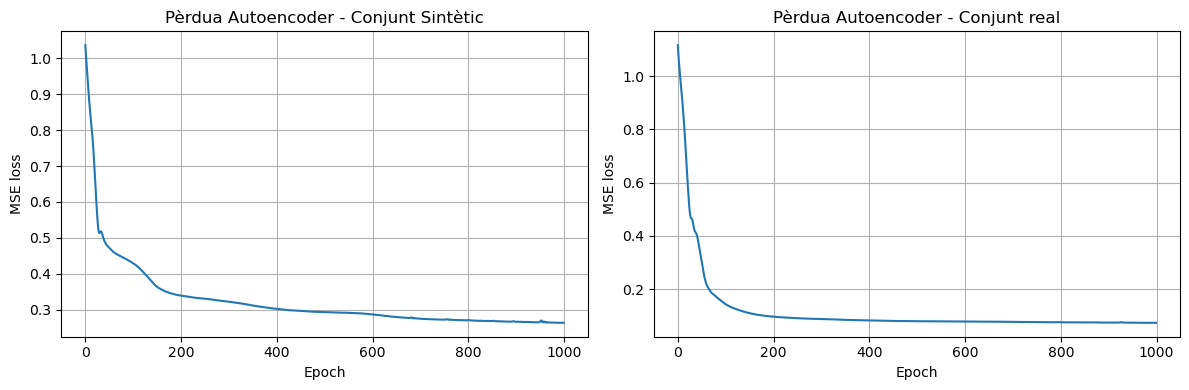

In [120]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(losses_synthetic)
axes[0].set_title("Pèrdua Autoencoder - Conjunt Sintètic")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE loss")
axes[0].grid(True)

axes[1].plot(losses_real)
axes[1].set_title("Pèrdua Autoencoder - Conjunt real")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("MSE loss")
axes[1].grid(True)

plt.tight_layout()
plt.show()

Les corbes de pèrdua mostren que l’autoencoder aprèn a reconstruir les dades d’entrada, ja que l’error MSE disminueix ràpidament durant les primeres epochs i després s’estabilitza. En el conjunt real la convergència és més ràpida i arriba a un error de reconstrucció més baix, mentre que en el conjunt sintètic la pèrdua final és més alta, indicant que la representació latent de dues dimensions conserva menys informació del conjunt original.

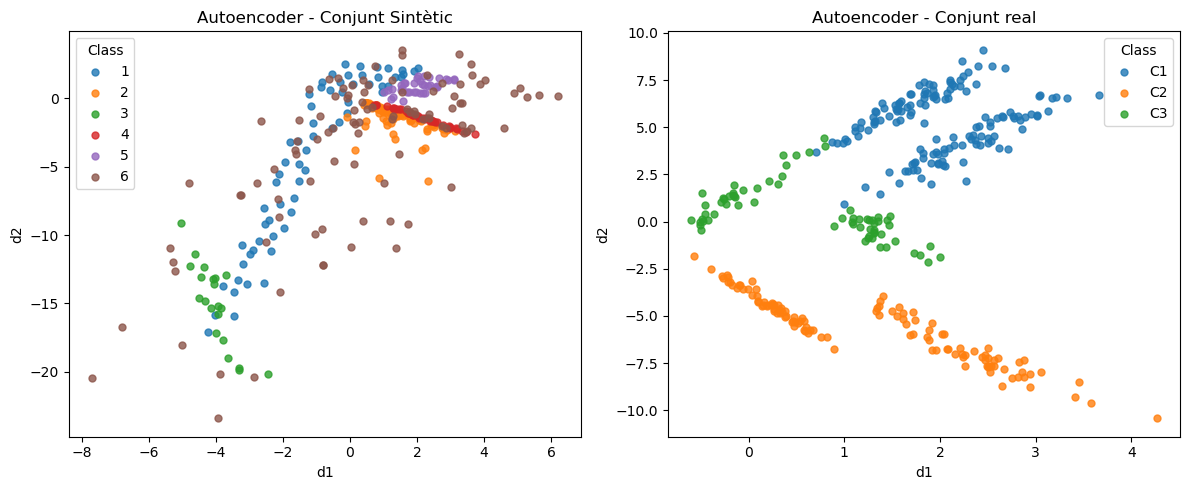

In [121]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for cls in sorted(df_synthetic_ae["class"].unique()):
    subset = df_synthetic_ae[df_synthetic_ae["class"] == cls]
    axes[0].scatter(subset["d1"], subset["d2"], label=cls, alpha=0.8, s=25)

axes[0].set_title("Autoencoder - Conjunt Sintètic")
axes[0].set_xlabel("d1")
axes[0].set_ylabel("d2")
axes[0].legend(title="Class")

for cls in sorted(df_real_ae["Class"].unique()):
    subset = df_real_ae[df_real_ae["Class"] == cls]
    axes[1].scatter(subset["d1"], subset["d2"], label=cls, alpha=0.8, s=25)

axes[1].set_title("Autoencoder - Conjunt real")
axes[1].set_xlabel("d1")
axes[1].set_ylabel("d2")
axes[1].legend(title="Class")

plt.tight_layout()
plt.show()

Pel conjunt sintètic s’ha utilitzat una arquitectura 4 → 8 → 2 → 8 → 4, mentre que per al conjunt real s’ha utilitzat una arquitectura 5 → 10 → 2 → 10 → 5. En tots dos casos, la dimensió latent és 2, la funció de pèrdua és MSE, l’optimitzador és Adam, el learning rate és 0.01 i l’entrenament s’ha fet durant 1000 epochs.

La projecció obtinguda amb l’autoencoder mostra diferències entre els dos conjunts de dades. En el conjunt sintètic, les classes apareixen parcialment ordenades en l’espai latent, però hi ha força solapament entre alguns grups, especialment amb la classe 6. Això indica que una representació latent de dues dimensions no separa completament les classes.

En el conjunt real, la representació latent separa millor les classes. La classe C2 queda clarament diferenciada en una zona de l’espai latent, mentre que C1 i C3 apareixen més properes en algunes regions. Aquest comportament és coherent amb el que ja s’havia observat amb PCA, t-SNE i clustering jeràrquic.

## 3.6 Self-Organizing Maps

Els Self-Organizing Maps són xarxes neuronals no supervisades que projecten les dades en una graella bidimensional preservant, en la mesura del possible, relacions de proximitat entre patrons. En aquest apartat s’entrenen diferents SOM amb almenys 100 neurones i es visualitzen mitjançant la U-matrix, el mapa de classe majoritària i els component planes.

In [122]:
from minisom import MiniSom

In [123]:
som_configs = [
    {"x": 10, "y": 10, "sigma": 1.0, "learning_rate": 0.5, "neighborhood_function": "gaussian"},
    {"x": 12, "y": 12, "sigma": 1.5, "learning_rate": 0.5, "neighborhood_function": "gaussian"},
    {"x": 15, "y": 10, "sigma": 1.0, "learning_rate": 0.3, "neighborhood_function": "bubble"},
]

In [124]:
#definim la funció d'entrenament

def train_som(X, config, num_iteration=5000):
    som = MiniSom(
        x=config["x"],
        y=config["y"],
        input_len=X.shape[1],
        sigma=config["sigma"],
        learning_rate=config["learning_rate"],
        neighborhood_function=config["neighborhood_function"],
        random_seed=42
    )
    som.random_weights_init(X.values)
    som.train_random(X.values, num_iteration=num_iteration)
    return som

In [125]:
#entrenem els soms amb conjunt sintètic

som_synthetic_results = []

for config in som_configs:
    som = train_som(X_synthetic_z, config)
    qe = som.quantization_error(X_synthetic_z.values)
    te = som.topographic_error(X_synthetic_z.values)
    som_synthetic_results.append((config, som, qe, te))

for config, som, qe, te in som_synthetic_results:
    print(config, "QE:", round(qe, 3), "TE:", round(te, 3))

{'x': 10, 'y': 10, 'sigma': 1.0, 'learning_rate': 0.5, 'neighborhood_function': 'gaussian'} QE: 0.417 TE: 0.281
{'x': 12, 'y': 12, 'sigma': 1.5, 'learning_rate': 0.5, 'neighborhood_function': 'gaussian'} QE: 0.421 TE: 0.125
{'x': 15, 'y': 10, 'sigma': 1.0, 'learning_rate': 0.3, 'neighborhood_function': 'bubble'} QE: 0.309 TE: 0.972


In [126]:
#entrenem els soms amb conjunt real

som_real_results = []

for config in som_configs:
    som = train_som(X_real_z, config)
    qe = som.quantization_error(X_real_z.values)
    te = som.topographic_error(X_real_z.values)
    som_real_results.append((config, som, qe, te))

for config, som, qe, te in som_real_results:
    print(config, "QE:", round(qe, 3), "TE:", round(te, 3))

{'x': 10, 'y': 10, 'sigma': 1.0, 'learning_rate': 0.5, 'neighborhood_function': 'gaussian'} QE: 0.333 TE: 0.183
{'x': 12, 'y': 12, 'sigma': 1.5, 'learning_rate': 0.5, 'neighborhood_function': 'gaussian'} QE: 0.306 TE: 0.087
{'x': 15, 'y': 10, 'sigma': 1.0, 'learning_rate': 0.3, 'neighborhood_function': 'bubble'} QE: 0.213 TE: 0.952


In [127]:
best_som_synthetic = som_synthetic_results[1][1]
best_som_real = som_real_results[1][1]

Tot i que la configuració amb funció de veïnatge `bubble` obté el menor quantization error, presenta un topographic error molt elevat. Per aquest motiu, s’ha seleccionat la configuració `12x12` amb veïnatge `gaussian`, que ofereix un millor equilibri entre quantization error i preservació de la topologia.

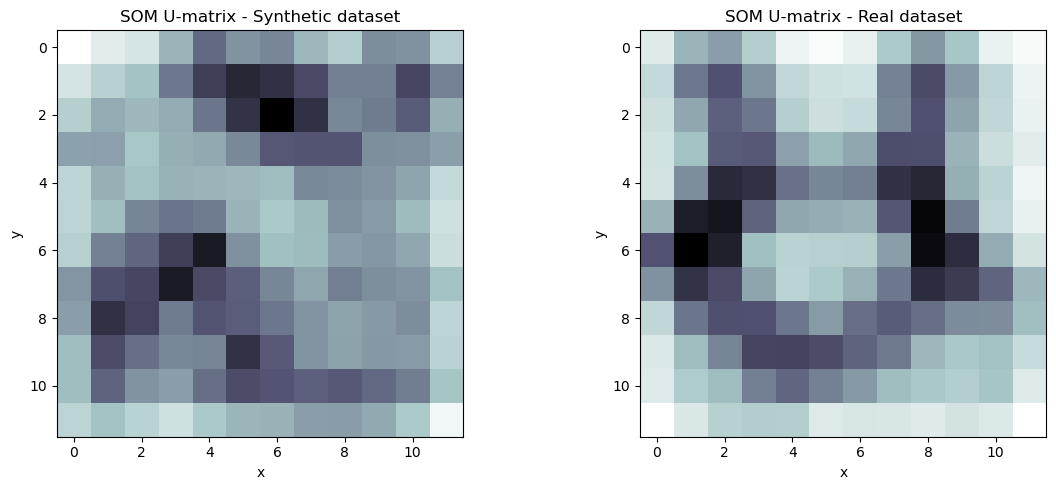

In [128]:
# U-matrix

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(best_som_synthetic.distance_map().T, cmap="bone_r")
axes[0].set_title("SOM U-matrix - Synthetic dataset")
axes[0].set_xlabel("x")
axes[0].set_ylabel("y")

axes[1].imshow(best_som_real.distance_map().T, cmap="bone_r")
axes[1].set_title("SOM U-matrix - Real dataset")
axes[1].set_xlabel("x")
axes[1].set_ylabel("y")

plt.tight_layout()
plt.show()

La U-matrix representa la distància mitjana entre cada neurona del SOM i les seves neurones veïnes. Les zones més fosques indiquen distàncies més grans i, per tant, possibles fronteres entre grups. En el conjunt sintètic s’observen diverses zones de separació, però no formen una estructura completament clara. En el conjunt real apareixen fronteres més marcades, especialment en algunes regions centrals del mapa, cosa que suggereix una separació més definida entre grups de patrons.

In [129]:
from collections import Counter
from matplotlib.colors import ListedColormap

In [130]:
#definim la funció per crear el mapa de classe majoritària
def majority_class_map(som, X, y, class_to_int):
    class_map = np.full((som._weights.shape[0], som._weights.shape[1]), np.nan)
    winners = {}

    for sample, label in zip(X.values, y.values):
        winner = som.winner(sample)
        winners.setdefault(winner, []).append(label)

    for position, labels in winners.items():
        majority_class = Counter(labels).most_common(1)[0][0]
        class_map[position] = class_to_int[majority_class]

    return class_map

In [131]:
synthetic_class_to_int = {1: 0, 2: 1, 3: 2, 4: 3, 5: 4, 6: 5}
real_class_to_int = {"C1": 0, "C2": 1, "C3": 2}

In [132]:
#apliquem la funció als diferents conjunts

synthetic_majority = majority_class_map(
    best_som_synthetic,
    X_synthetic_z,
    y_synthetic,
    synthetic_class_to_int
)

real_majority = majority_class_map(
    best_som_real,
    X_real_z,
    y_real,
    real_class_to_int
)

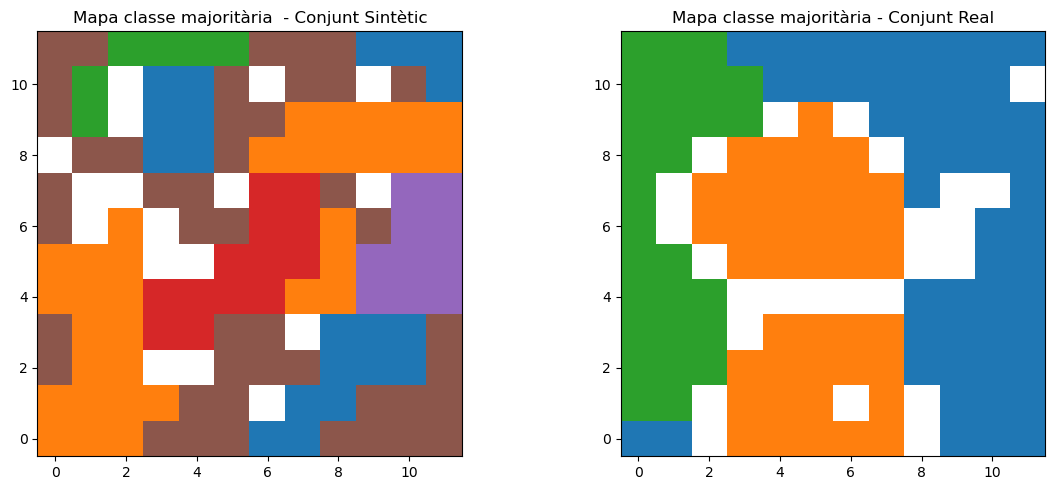

In [133]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

synthetic_cmap = ListedColormap(["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple", "tab:brown"])
real_cmap = ListedColormap(["tab:blue", "tab:orange", "tab:green"])

im0 = axes[0].imshow(synthetic_majority.T, cmap=synthetic_cmap, origin="lower")
axes[0].set_title("Mapa classe majoritària  - Conjunt Sintètic")

im1 = axes[1].imshow(real_majority.T, cmap=real_cmap, origin="lower")
axes[1].set_title("Mapa classe majoritària - Conjunt Real")

plt.tight_layout()
plt.show()

En el mapa del conjunt sintètic, els colors representen la classe majoritària de cada neurona: blau = classe 1, taronja = classe 2, verd = classe 3, vermell = classe 4, lila = classe 5 i marró = classe 6. Les cel·les blanques corresponen a neurones sense cap patró assignat. I en el mapa del conjunt real, els colors representen la classe majoritària de cada neurona: blau = C1, taronja = C2 i verd = C3. Les cel·les blanques corresponen a neurones sense cap patró assignat.

En el conjunt sintètic, les classes apareixen distribuïdes de manera més fragmentada, amb diverses regions separades per a una mateixa classe. En canvi, en el conjunt real les classes formen regions més compactes i diferenciades, cosa que indica una estructura més clara en el mapa SOM.

Després de comparar els SOM entrenats, s’ha seleccionat com a “millor” mapa el SOM del conjunt real amb configuració 12x12, sigma = 1.5, learning rate = 0.5 i funció de veïnatge gaussian. Aquesta selecció es basa en el bon equilibri entre quantization error i topographic error, i també en el fet que el mapa de classe majoritària mostra regions més compactes i interpretables que en el conjunt sintètic. Per aquest mapa es representen els component planes.

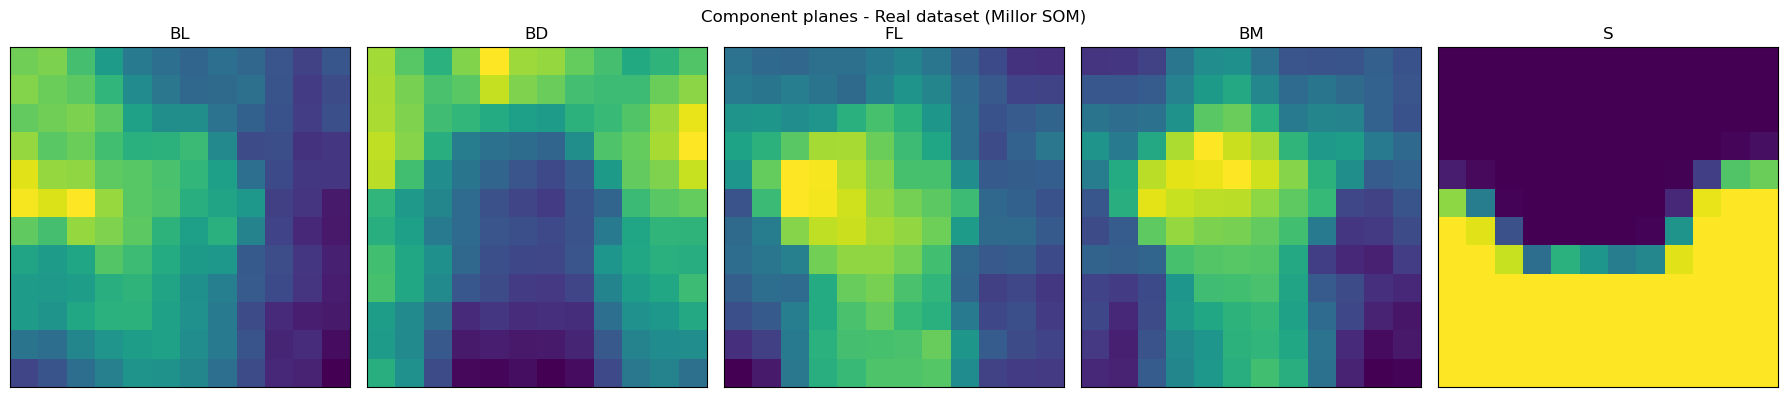

In [134]:
weights_real = best_som_real.get_weights()

fig, axes = plt.subplots(1, X_real_z.shape[1], figsize=(18, 4))

for i, col in enumerate(X_real_z.columns):
    axes[i].imshow(weights_real[:, :, i].T, cmap="viridis", origin="lower")
    axes[i].set_title(col)
    axes[i].set_xticks([])
    axes[i].set_yticks([])

plt.suptitle("Component planes - Real dataset (Millor SOM)")
plt.tight_layout()
plt.show()

Els component planes mostren com es distribueix cada variable original sobre el mapa SOM seleccionat. Els colors més clars indiquen valors més alts del pes de la variable en aquella zona del mapa, mentre que els colors més foscos indiquen valors més baixos.

En el mapa del conjunt real s’observa que variables com `BL`, `FL` i `BM` presenten gradients espacials clars, cosa que indica que contribueixen a l’organització del SOM. La variable `S`, en canvi, mostra una separació molt marcada en dues zones, coherent amb el fet que és una variable binària. Aquestes visualitzacions ajuden a interpretar quines variables expliquen les diferents regions del mapa.

## 4. Conclusions finals

En el conjunt sintètic, les tècniques aplicades mostren una separació parcial de les classes, però també força solapament entre diversos grups. PCA permet observar una primera estructura global, però les dues primeres components no conserven tota la informació del conjunt original. t-SNE ofereix una visualització més clara d’algunes agrupacions, tot i que depèn del valor de `perplexity`. Els resultats de k-means i clustering jeràrquic confirmen que les classes no es recuperen de manera perfecta només a partir de les distàncies entre patrons. L’autoencoder i el SOM també mostren una certa organització de les dades, però amb classes més fragmentades.

En el conjunt real, la separació entre classes és més clara. PCA, t-SNE i l’autoencoder mostren que la classe C2 tendeix a quedar força diferenciada, mentre que C1 i C3 apareixen més properes en algunes zones. k-means obté una bona correspondència amb les classes reals, especialment per valors baixos de k, tot i que el millor resultat no coincideix necessàriament amb el nombre real de classes. Els dendrogrames i el SOM també mostren una estructura més compacta i interpretable que en el conjunt sintètic.

En general, cap tècnica no supervisada recupera necessàriament les classes reals de manera exacta, ja que aquestes classes no s’utilitzen durant l’entrenament. Tot i això, la comparació de les diferents visualitzacions i agrupacions permet entendre millor l’estructura interna de les dades. El conjunt real presenta una organització més clara, mentre que el conjunt sintètic resulta més difícil de separar completament en dues dimensions.